<a href="https://colab.research.google.com/github/priyahappy003/Delta/blob/main/ProjectWork_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1. Install required libraries
Explanation: Installs the libraries required for machine learning, visualization and the frontend.

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn joblib gradio

Cell 2. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance

print("All libraries imported successfully!")

All libraries imported successfully!


Cell 3. Load your dataset
Explanation: This uses the Google Sheet you shared earlier. The sheet must be publicly accessible or accessible through its sharing settings.

In [3]:
SHEET_ID = "1z5WFArY9DnSyq854vktucDPxs6qvx8sYEDViOfVMp4M"
GID = "0"

DATASET_URL = (
    f"https://docs.google.com/spreadsheets/d/"
    f"{SHEET_ID}/export?format=csv&gid={GID}"
)

df = pd.read_csv(DATASET_URL)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (4000, 11)


,vehicle_density,avg_vehicle_speed,speed_std,lane_occupancy,queue_length,edge_density,optical_flow_mag,shadow_fraction,time_of_day_norm,road_width_norm,label
0,23.865083,56.660004,5.737366,0.448821,13.583201,0.412864,0.395673,0.127440,0.334763,0.990240,1
1,15.755624,67.562554,3.761696,0.203759,9.119581,0.343221,0.877234,0.197382,0.688851,0.663392,0
2,14.719641,60.782993,3.558324,0.259485,6.966499,0.336209,0.455082,0.196271,0.279968,0.905470,0
3,14.719814,72.431960,0.560680,0.210146,4.188474,0.277365,0.730398,0.090561,0.643183,0.891052,0
4,43.372854,33.125925,12.071894,0.685767,9.363837,0.643574,0.210252,0.140736,0.957246,0.944823,1


Cell 4. Understand the dataset
Explanation: Checks the column names, data types, missing values and statistical information.

In [4]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

First 5 rows:


,vehicle_density,avg_vehicle_speed,speed_std,lane_occupancy,queue_length,edge_density,optical_flow_mag,shadow_fraction,time_of_day_norm,road_width_norm,label
0,23.865083,56.660004,5.737366,0.448821,13.583201,0.412864,0.395673,0.127440,0.334763,0.990240,1
1,15.755624,67.562554,3.761696,0.203759,9.119581,0.343221,0.877234,0.197382,0.688851,0.663392,0
2,14.719641,60.782993,3.558324,0.259485,6.966499,0.336209,0.455082,0.196271,0.279968,0.905470,0
3,14.719814,72.431960,0.560680,0.210146,4.188474,0.277365,0.730398,0.090561,0.643183,0.891052,0
4,43.372854,33.125925,12.071894,0.685767,9.363837,0.643574,0.210252,0.140736,0.957246,0.944823,1



Column names:
['vehicle_density', 'avg_vehicle_speed', 'speed_std', 'lane_occupancy', 'queue_length', 'edge_density', 'optical_flow_mag', 'shadow_fraction', 'time_of_day_norm', 'road_width_norm', 'label']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   vehicle_density    4000 non-null   float64
 1   avg_vehicle_speed  4000 non-null   float64
 2   speed_std          4000 non-null   float64
 3   lane_occupancy     4000 non-null   float64
 4   queue_length       4000 non-null   float64
 5   edge_density       4000 non-null   float64
 6   optical_flow_mag   4000 non-null   float64
 7   shadow_fraction    4000 non-null   float64
 8   time_of_day_norm   4000 non-null   float64
 9   road_width_norm    4000 non-null   float64
 10  label              4000 non-null   int64  
dtypes: float64(10), int64(1)
memory usag

,count,mean,std,min,25%,50%,75%,max
vehicle_density,4000.0,20.116392,12.604460,0.326223,10.933062,17.535134,26.604050,116.858197
avg_vehicle_speed,4000.0,55.895658,16.584939,5.000000,46.412276,57.994579,67.643562,90.000000
speed_std,4000.0,6.351934,4.384556,0.002577,2.939375,5.780743,8.810003,37.937951
lane_occupancy,4000.0,0.335010,0.209370,0.000000,0.181017,0.297576,0.453174,1.000000
queue_length,4000.0,7.959204,5.666685,0.109818,3.922624,6.521932,10.463889,43.285818
edge_density,4000.0,0.401409,0.135858,0.124681,0.303003,0.378663,0.475957,1.000000
optical_flow_mag,4000.0,0.560445,0.182694,0.000000,0.453835,0.576044,0.691486,1.000000
shadow_fraction,4000.0,0.150426,0.078367,0.000000,0.094160,0.148212,0.202875,0.493909
time_of_day_norm,4000.0,0.497673,0.289784,0.000094,0.241122,0.495915,0.752959,0.999957
road_width_norm,4000.0,0.699993,0.172762,0.400063,0.549426,0.701816,0.845197,0.999905


Cell 5. Clean the dataset
Explanation: Removes duplicate records, empty rows and empty columns. It also standardizes column names.

In [5]:
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

df = df.drop_duplicates()
df = df.dropna(how="all")
df = df.dropna(axis=1, how="all")

print("Cleaned dataset shape:", df.shape)
print("\nUpdated columns:")
print(df.columns.tolist())

display(df.head())

Cleaned dataset shape: (4000, 11)

Updated columns:
['vehicle_density', 'avg_vehicle_speed', 'speed_std', 'lane_occupancy', 'queue_length', 'edge_density', 'optical_flow_mag', 'shadow_fraction', 'time_of_day_norm', 'road_width_norm', 'label']


,vehicle_density,avg_vehicle_speed,speed_std,lane_occupancy,queue_length,edge_density,optical_flow_mag,shadow_fraction,time_of_day_norm,road_width_norm,label
0,23.865083,56.660004,5.737366,0.448821,13.583201,0.412864,0.395673,0.127440,0.334763,0.990240,1
1,15.755624,67.562554,3.761696,0.203759,9.119581,0.343221,0.877234,0.197382,0.688851,0.663392,0
2,14.719641,60.782993,3.558324,0.259485,6.966499,0.336209,0.455082,0.196271,0.279968,0.905470,0
3,14.719814,72.431960,0.560680,0.210146,4.188474,0.277365,0.730398,0.090561,0.643183,0.891052,0
4,43.372854,33.125925,12.071894,0.685767,9.363837,0.643574,0.210252,0.140736,0.957246,0.944823,1


Cell 6. Identify the target column
Explanation: The target column is what the model learns to predict. For example, it could contain labels such as Normal, Congestion or Incident—but you must use the actual labels in your dataset.

In [6]:
print("Available columns:")
for col in df.columns:
    print(col, ":", df[col].nunique(), "unique values")

print("\nPossible target columns:")
for col in df.columns:
    if df[col].nunique() <= 20:
        print(col, "->", df[col].unique()[:20])

Available columns:
vehicle_density : 4000 unique values
avg_vehicle_speed : 3947 unique values
speed_std : 4000 unique values
lane_occupancy : 3924 unique values
queue_length : 4000 unique values
edge_density : 3994 unique values
optical_flow_mag : 3978 unique values
shadow_fraction : 3879 unique values
time_of_day_norm : 4000 unique values
road_width_norm : 4000 unique values
label : 2 unique values

Possible target columns:
label -> [1 0]


In [7]:
TARGET_COLUMN = "label"

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        "Target column not found. Check the column names above "
        "and update TARGET_COLUMN."
    )

print("Selected target:", TARGET_COLUMN)
print("\nTarget distribution:")
print(df[TARGET_COLUMN].value_counts(dropna=False))

Selected target: label

Target distribution:
label
0    2200
1    1800
Name: count, dtype: int64


Cell 7. Prepare features and labels
Explanation:
- X contains the input features used for prediction.
- y contains the target labels.
- ID-like columns are excluded because they usually identify records rather than describe traffic conditions.
- Constant columns and rows without labels are removed.


In [8]:
df = df.dropna(subset=[TARGET_COLUMN]).copy()

X = df.drop(columns=[TARGET_COLUMN]).copy()
y = df[TARGET_COLUMN].copy()

# Remove columns that appear to be record identifiers
id_columns = [
    col for col in X.columns
    if col == "id"
    or col.endswith("_id")
    or col in ["serial_no", "record_id"]
]

X = X.drop(columns=id_columns, errors="ignore")

# Remove constant columns
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_columns, errors="ignore")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts())

Features shape: (4000, 10)
Target shape: (4000,)

Features:
['vehicle_density', 'avg_vehicle_speed', 'speed_std', 'lane_occupancy', 'queue_length', 'edge_density', 'optical_flow_mag', 'shadow_fraction', 'time_of_day_norm', 'road_width_norm']

Target classes:
label
0    2200
1    1800
Name: count, dtype: int64


Cell 8. Visualize target distribution
Explanation: Displays the number of examples belonging to each traffic category. This helps identify class imbalance.


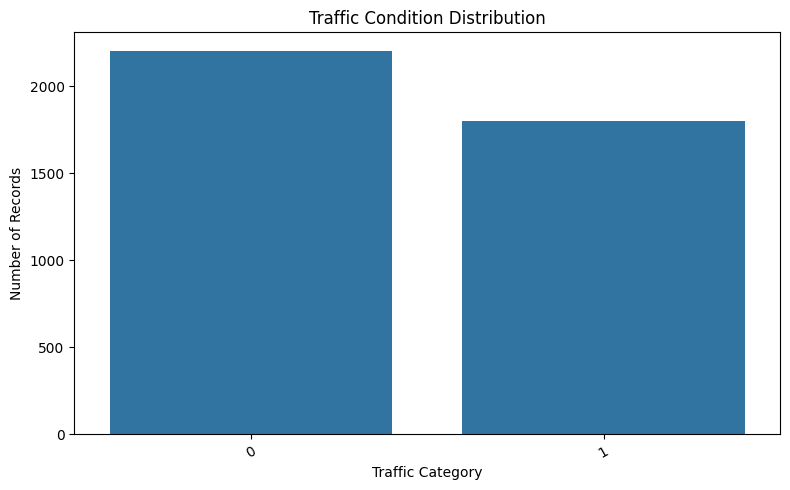

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x=y.astype(str),
    order=y.astype(str).value_counts().index
)

plt.title("Traffic Condition Distribution")
plt.xlabel("Traffic Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Cell 9. Identify numerical and categorical features
Explanation: Numerical columns are imputed and scaled. Categorical columns are imputed and converted into numerical form using one-hot encoding.

In [10]:
numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["int64", "float64", "int32", "float32"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['vehicle_density', 'avg_vehicle_speed', 'speed_std', 'lane_occupancy', 'queue_length', 'edge_density', 'optical_flow_mag', 'shadow_fraction', 'time_of_day_norm', 'road_width_norm']

Categorical features:
[]


Cell 10. Split the dataset
Explanation: Uses 80% of the data for training and 20% for testing. The test data is kept separate to evaluate performance on unseen records.

In [11]:
try:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
except ValueError:
    print("Stratified split was not possible. Using a normal split.")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 3200
Testing records: 800


Cell 11. Create preprocessing pipeline
Explanation: Missing numerical values are replaced with the median and numerical features are scaled. Missing categorical values are filled with the most frequent category, then one-hot encoded.

In [12]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


Part 3 — Train multiple machine-learning models
Cell 12. Define machine-learning models
Explanation: We will compare five algorithms. Each model is placed inside a pipeline so the same preprocessing steps are applied consistently


In [13]:
models_to_train = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        class_weight="balanced",
        probability=True,
        random_state=42
    )
}

trained_models = {}

for name, estimator in models_to_train.items():

    trained_models[name] = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", estimator)
        ]
    )

print("Five model pipelines created!")

Five model pipelines created!


Cell 13. Train all models
Explanation: Each model learns from the training data. The test data is not used during model fitting.

In [14]:
for name, model in trained_models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    print(name, "trained successfully!\n")

Training: Logistic Regression
Logistic Regression trained successfully!

Training: Decision Tree
Decision Tree trained successfully!

Training: Random Forest
Random Forest trained successfully!

Training: Extra Trees
Extra Trees trained successfully!

Training: SVM
SVM trained successfully!



Cell 14. Compare model performance
Explanation: Evaluates all five models using accuracy, weighted precision, weighted recall and weighted F1-score.

In [15]:
results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8475,0.8475,0.8475,0.8475
1,Random Forest,0.8475,0.8480,0.8475,0.8468
2,SVM,0.8438,0.8438,0.8438,0.8438
3,Extra Trees,0.8388,0.8387,0.8388,0.8383
4,Decision Tree,0.7962,0.7977,0.7962,0.7966


Cell 15. Visualize model comparison

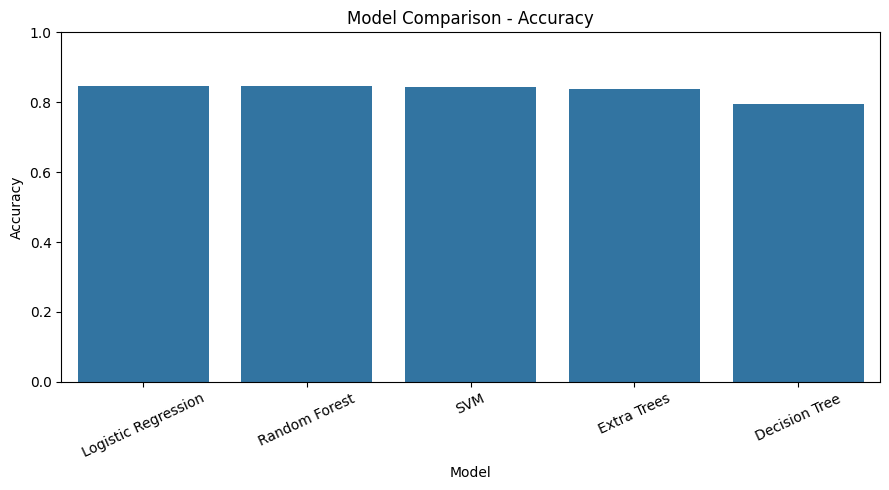

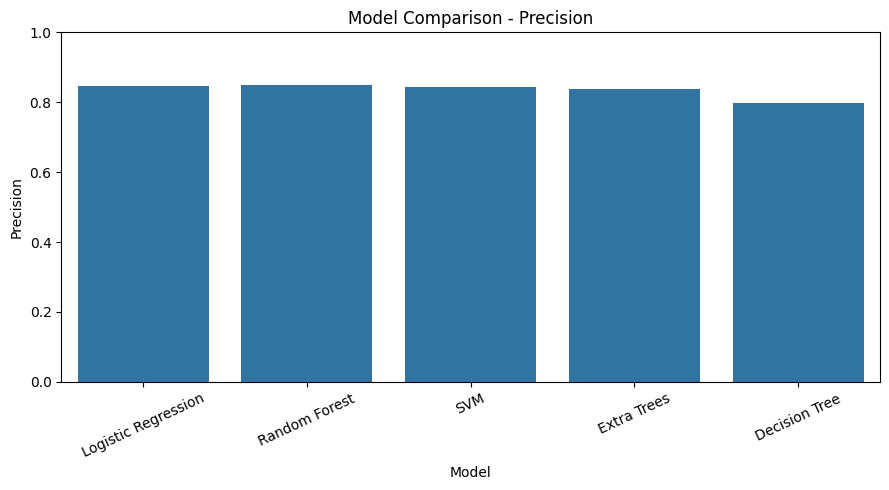

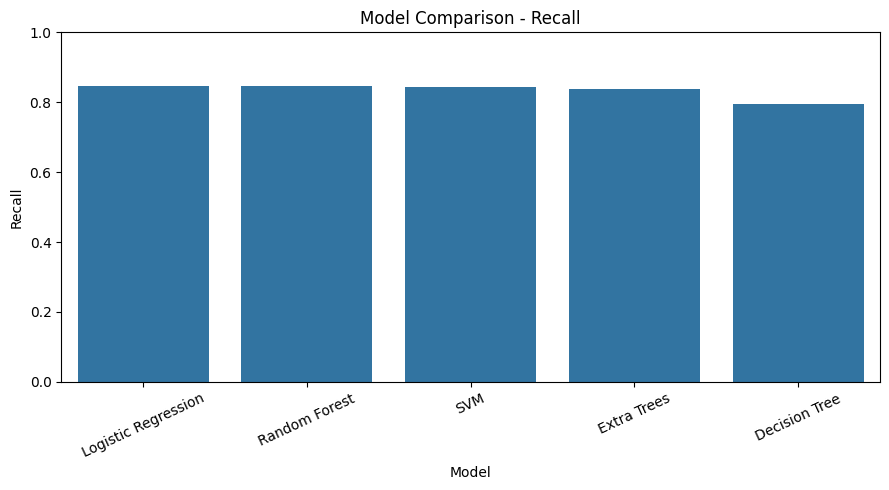

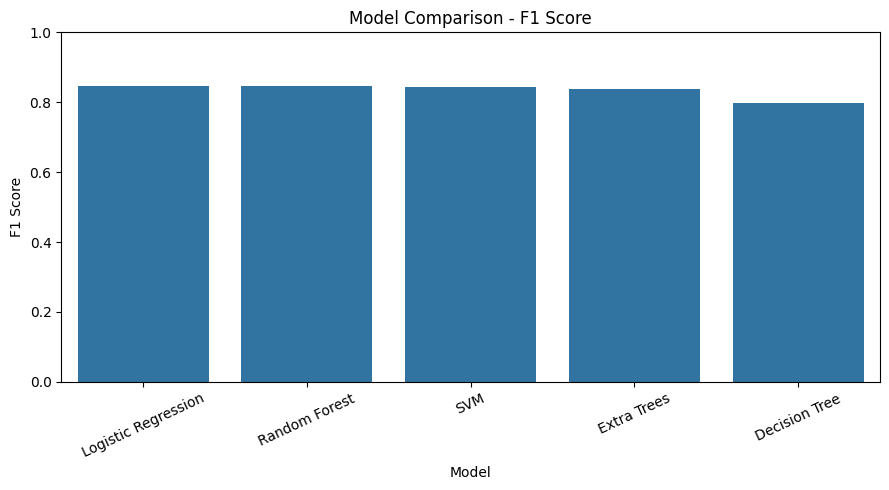

In [16]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=25)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

Cell 16. Select the best-performing model
Explanation: Selects the model with the highest weighted F1-score as the initial candidate. You should also inspect the per-class recall before finalizing it, especially for the congestion and incident categories.

In [17]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Best model based on weighted F1-score:")
print(best_model_name)

best_predictions = best_model.predict(X_test)

Best model based on weighted F1-score:
Logistic Regression


Part 4 — Detailed model evaluation
Cell 17. Classification report
Explanation: Shows precision, recall and F1-score separately for every target class.

In [18]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86       440
           1       0.83      0.83      0.83       360

    accuracy                           0.85       800
   macro avg       0.85      0.85      0.85       800
weighted avg       0.85      0.85      0.85       800



Cell 18. Confusion matrix
Explanation: Shows correct and incorrect predictions for each class.

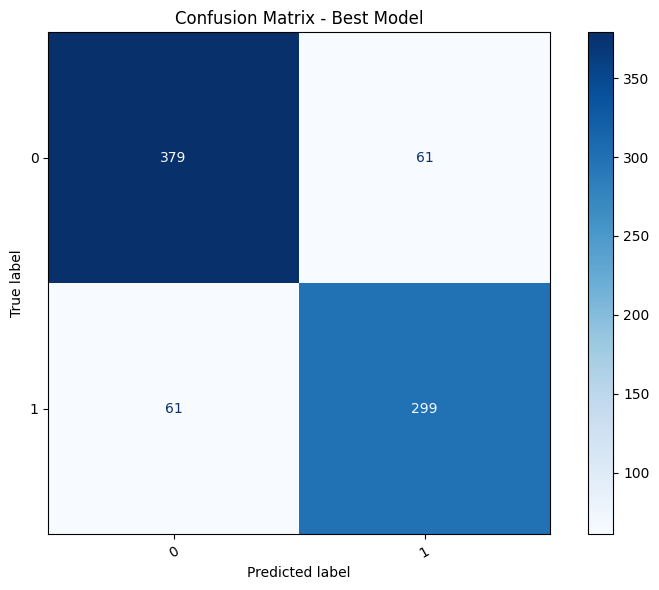

In [19]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=best_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", ax=ax, xticks_rotation=30)

plt.title("Confusion Matrix - Best Model")
plt.tight_layout()
plt.show()

Cell 19. Check class-wise recall
Explanation: Helps you see whether the model is correctly identifying each traffic condition.

In [20]:
report = classification_report(
    y_test,
    best_predictions,
    output_dict=True,
    zero_division=0
)

class_recall = pd.DataFrame([
    {
        "Class": label,
        "Recall": values["recall"],
        "Precision": values["precision"],
        "F1 Score": values["f1-score"]
    }
    for label, values in report.items()
    if isinstance(values, dict) and "recall" in values
])

display(class_recall.round(4))

,Class,Recall,Precision,F1 Score
0,0,0.8614,0.8614,0.8614
1,1,0.8306,0.8306,0.8306
2,macro avg,0.8460,0.8460,0.8460
3,weighted avg,0.8475,0.8475,0.8475


Part 5 — Feature importance and error analysis
Cell 20. Find important features
Explanation: Permutation importance measures how much model performance decreases when a feature is shuffled. It helps identify which input features contribute to predictions.

We use the original feature columns so that the results are easier to interpret.

In [21]:
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="f1_weighted",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df)

,Feature,Importance,Std
0,avg_vehicle_speed,0.168733,0.011957
1,vehicle_density,0.041334,0.007616
2,lane_occupancy,0.015741,0.004594
3,queue_length,0.012028,0.002625
4,shadow_fraction,0.001532,0.003484
5,road_width_norm,0.001240,0.002110
6,time_of_day_norm,0.000992,0.000496
7,speed_std,0.000270,0.002313
8,optical_flow_mag,0.000168,0.003274
9,edge_density,-0.001768,0.005504


Cell 21. Plot feature importance

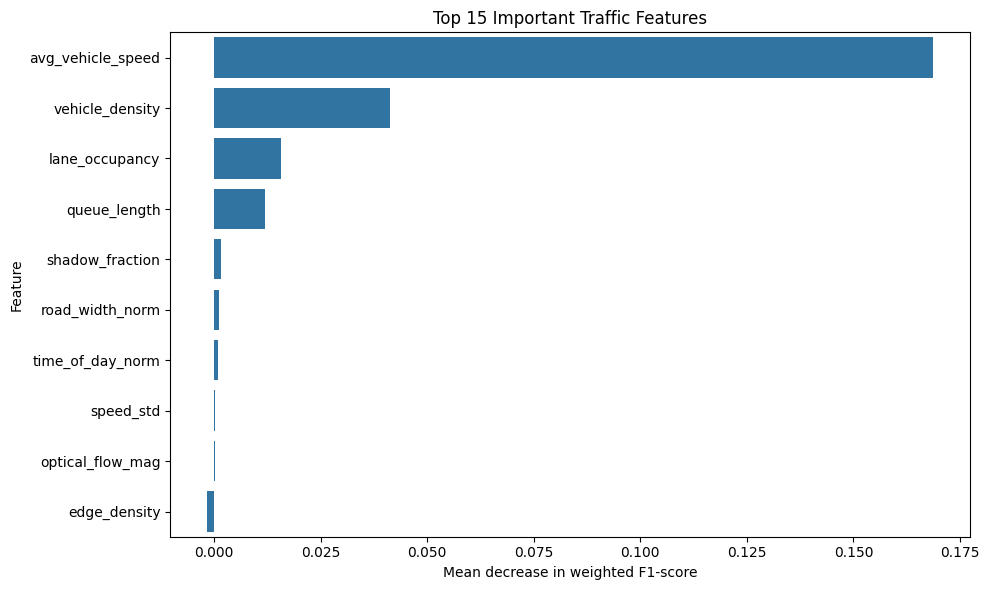

In [22]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Traffic Features")
plt.xlabel("Mean decrease in weighted F1-score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Cell 22. Inspect incorrect predictions
Explanation: Identifies records where the model predicted a different class from the actual label.

In [23]:
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test.values
error_analysis["Predicted"] = best_predictions

incorrect_predictions = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
]

print("Total incorrect predictions:", len(incorrect_predictions))

display(incorrect_predictions.head(20))

Total incorrect predictions: 122


,vehicle_density,avg_vehicle_speed,speed_std,lane_occupancy,queue_length,edge_density,optical_flow_mag,shadow_fraction,time_of_day_norm,road_width_norm,Actual,Predicted
1438,16.715296,58.854514,6.926243,0.217458,9.250939,0.313273,0.561527,0.038033,0.925918,0.752283,1,0
1017,24.040555,53.883809,5.765739,0.432766,10.920568,0.561379,0.593957,0.237400,0.151693,0.876019,0,1
3902,28.014960,66.367649,9.718898,0.457149,14.025592,0.460434,0.645283,0.069977,0.813982,0.430108,1,0
1205,23.887061,57.564546,12.062575,0.395697,5.967987,0.465194,0.540519,0.234353,0.228196,0.465492,0,1
1241,15.285676,52.966053,3.298254,0.286777,8.110841,0.375330,0.453408,0.202233,0.176129,0.737702,0,1
1473,10.732647,55.864435,3.242524,0.179577,6.233626,0.249260,0.628286,0.207311,0.753786,0.452362,1,0
724,13.942139,49.187333,7.977684,0.293868,5.803517,0.275893,0.506046,0.168219,0.347368,0.607220,0,1
3089,27.701389,60.900393,6.651702,0.484505,10.554227,0.455207,0.705131,0.221814,0.800768,0.883758,0,1
1127,15.149616,64.810660,2.855842,0.310368,5.777030,0.388213,0.588516,0.221898,0.031684,0.802756,1,0
2970,22.141148,64.753408,1.443303,0.453135,6.766278,0.489916,0.713856,0.202213,0.645243,0.686532,1,0


Cell 23. Generate a prediction comparison table

In [24]:
prediction_table = X_test.copy()

prediction_table["Actual"] = y_test.values

for name, model in trained_models.items():

    prediction_table[name] = model.predict(X_test)

display(prediction_table.head(20))

,vehicle_density,avg_vehicle_speed,speed_std,lane_occupancy,queue_length,edge_density,optical_flow_mag,shadow_fraction,time_of_day_norm,road_width_norm,Actual,Logistic Regression,Decision Tree,Random Forest,Extra Trees,SVM
2875,20.037798,57.324750,7.788362,0.386851,6.647661,0.361316,0.500342,0.115680,0.798990,0.704532,1,1,0,1,1,1
709,4.708920,90.000000,3.512894,0.081238,1.172056,0.276205,0.822506,0.180256,0.800324,0.633030,0,0,0,0,0,0
1588,10.179287,69.690895,6.968109,0.195317,5.808967,0.341194,0.702962,0.111647,0.035135,0.763501,0,0,0,0,0,0
2515,14.881664,42.362438,7.945995,0.224763,4.763739,0.312076,0.396137,0.238830,0.548466,0.923450,1,1,1,1,1,1
1438,16.715296,58.854514,6.926243,0.217458,9.250939,0.313273,0.561527,0.038033,0.925918,0.752283,1,0,0,0,0,0
2160,39.464756,39.422935,14.619552,0.676647,18.304921,0.619773,0.330421,0.131690,0.739505,0.757732,1,1,1,1,1,1
2803,6.591662,83.093683,0.249481,0.000000,2.636853,0.199060,0.910600,0.205276,0.450890,0.492253,0,0,0,0,0,0
3831,34.959012,28.232152,14.404643,0.669743,18.645386,0.523861,0.385578,0.090452,0.568599,0.433210,1,1,1,1,1,1
270,10.330268,66.896479,2.271134,0.154961,4.009547,0.238864,0.621725,0.171647,0.114113,0.806572,0,0,0,0,0,0
403,11.877802,70.006353,6.022645,0.149210,3.844110,0.363333,0.730162,0.272334,0.621069,0.732568,0,0,0,0,0,0


Part 6 — Test the model manually
Cell 24. Predict an individual test record
Explanation: Takes one unseen test record and asks the trained models to predict its traffic category.

In [25]:
sample_input = X_test.iloc[[0]]

print("Input traffic data:")
display(sample_input)

print("Actual traffic condition:")
print(y_test.iloc[0])

for name, model in trained_models.items():

    prediction = model.predict(sample_input)[0]

    print(name, "prediction:", prediction)

Input traffic data:


,vehicle_density,avg_vehicle_speed,speed_std,lane_occupancy,queue_length,edge_density,optical_flow_mag,shadow_fraction,time_of_day_norm,road_width_norm
2875,20.037798,57.32475,7.788362,0.386851,6.647661,0.361316,0.500342,0.11568,0.79899,0.704532


Actual traffic condition:
1
Logistic Regression prediction: 1
Decision Tree prediction: 0
Random Forest prediction: 1
Extra Trees prediction: 1
SVM prediction: 1


Cell 25. Display prediction probabilities
Explanation: Shows the estimated probability of each class for a model that supports predict_proba().

In [26]:
if hasattr(best_model, "predict_proba"):

    probabilities = best_model.predict_proba(sample_input)[0]

    probability_df = pd.DataFrame({
        "Traffic Category": best_model.classes_,
        "Probability": probabilities
    })

    display(probability_df.sort_values(
        by="Probability",
        ascending=False
    ))

else:
    print("Probability prediction is not supported.")

,Traffic Category,Probability
1,1,0.555743
0,0,0.444257


Part 7 — Save the model and export results
Cell 26. Save the trained model
Explanation: Saves the entire fitted pipeline, including preprocessing and the classifier. This is important because future predictions must use the same preprocessing.

In [27]:
joblib.dump(
    best_model,
    "traffic_congestion_model.joblib"
)

print("Model saved successfully!")
print("Selected model:", best_model_name)

Model saved successfully!
Selected model: Logistic Regression


Cell 27. Export predictions and feature importance

In [28]:
prediction_table.to_csv(
    "traffic_predictions.csv",
    index=False
)

importance_df.to_csv(
    "traffic_feature_importance.csv",
    index=False
)

results_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("All CSV files exported!")

All CSV files exported!


Cell 28. Download your files

In [29]:
from google.colab import files

files.download("traffic_congestion_model.joblib")
files.download("traffic_predictions.csv")
files.download("traffic_feature_importance.csv")
files.download("model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Part 8 — Build a simple frontend using Gradio
Frontend section
This is the part that turns your ML notebook into an interactive demonstration.

A user will be able to:
- Enter traffic measurements.
- Select categorical values where applicable.
- Click the Predict button.
- View the predicted traffic condition.
- View the estimated class probabilities.
The frontend will use your already-trained model. It will not train a new model every time someone clicks the button.

In [30]:
# Cell 29. Install and import Gradio
!pip install -q gradio

import gradio as gr

print("Gradio imported successfully!")

Gradio imported successfully!


Cell 30. Choose the model for the frontend
Explanation: Uses the best-performing model selected earlier.

In [31]:
demo_model = best_model

print("Frontend will use:", best_model_name)

Frontend will use: Logistic Regression


Cell 31. Create frontend input fields
Explanation: Automatically creates an input field for every feature in your dataset. Numerical features get number inputs; categorical features get dropdowns when they have a manageable number of known values.

In [32]:
input_components = []

for col in X_train.columns:

    if col in numeric_features:

        median_value = X_train[col].median()

        if pd.isna(median_value):
            median_value = 0

        component = gr.Number(
            label=col,
            value=float(median_value)
        )

    else:

        choices = sorted(
            X_train[col].dropna().astype(str).unique().tolist()
        )

        if 0 < len(choices) <= 30:

            component = gr.Dropdown(
                choices=choices,
                value=choices[0],
                label=col,
                allow_custom_value=False
            )

        else:

            component = gr.Textbox(
                label=col,
                placeholder=f"Enter {col}"
            )

    input_components.append(component)

print("Frontend input fields created:", len(input_components))

Frontend input fields created: 10


Cell 32. Create the prediction function
Explanation: Takes values entered by the user, constructs a DataFrame with the correct feature names, and passes it to the trained model.

In [33]:
def predict_traffic(*values):

    input_data = pd.DataFrame(
        [values],
        columns=X_train.columns
    )

    # Convert numerical fields to numeric values
    for col in numeric_features:
        input_data[col] = pd.to_numeric(
            input_data[col],
            errors="coerce"
        )

    prediction = demo_model.predict(input_data)[0]

    result = f"Predicted Traffic Condition: {prediction}"

    probability_output = {}

    if hasattr(demo_model, "predict_proba"):

        probabilities = demo_model.predict_proba(input_data)[0]

        probability_output = {
            str(label): round(float(probability), 4)
            for label, probability in zip(
                demo_model.classes_,
                probabilities
            )
        }

    return result, probability_output

Cell 33. Launch the frontend
Explanation: Creates the interactive web interface and launches it inside Google Colab.

In [34]:
demo = gr.Interface(
    fn=predict_traffic,
    inputs=input_components,
    outputs=[
        gr.Textbox(label="Predicted Traffic Condition"),
        gr.JSON(label="Class Probabilities")
    ],
    title="AI-Based Traffic Congestion and Incident Detection",
    description=(
        "Enter traffic measurements to predict "
        "the traffic condition using a trained "
        "machine-learning model."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://af9cdf8e58f86bcf6f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Part 9 — Optional: Test your saved model
Cell 34. Load the saved model again
Explanation: Demonstrates that the saved model can be reused without retraining it.

In [35]:
loaded_model = joblib.load(
    "traffic_congestion_model.joblib"
)

sample_prediction = loaded_model.predict(
    X_test.iloc[[0]]
)

print("Prediction from loaded model:", sample_prediction[0])
print("Actual label:", y_test.iloc[0])

Prediction from loaded model: 1
Actual label: 1
